# SentinelX AI — Analyse exploratoire des données (EDA)

**Dataset NASA C-MAPSS FD001 · Étape S2 du projet**

Ce notebook explore les données **avant** de construire un modèle. À la fin, nous devons pouvoir répondre à cinq questions :

1. Qu'avons-nous appris sur les données ?
2. Quels capteurs semblent utiles, et pourquoi ?
3. Quels problèmes avons-nous détectés ?
4. Comment construisons-nous la cible RUL ?
5. Quelles décisions transmettons-nous au notebook suivant (la baseline) ?

### Quelques mots à connaître

| Mot | Signification |
|---|---|
| **Cycle** | Une période de fonctionnement du moteur (par exemple un vol). |
| **Trajectoire** | Toutes les mesures d'un même moteur, du premier cycle jusqu'au dernier. |
| **RUL** (*Remaining Useful Life*) | Nombre de cycles qu'il reste avant la panne. C'est ce que SentinelX AI devra prédire. |
| **Data leakage** (fuite d'information) | Le modèle voit pendant l'entraînement une information qu'il n'aura pas en situation réelle. Ses scores paraissent alors meilleurs qu'ils ne le sont. |
| **Validation** | Des moteurs mis de côté pour vérifier le modèle sur des données qu'il n'a jamais vues. |

### Plan

1. Préparation du notebook
2. Chargement des données
3. Qualité des données
4. Durée de vie des moteurs
5. Séparation entraînement / validation
6. Choix des capteurs
7. Construction de la cible RUL
8. Évolution des capteurs avant la panne
9. Lien entre les capteurs et le RUL
10. Capteurs redondants
11. Vérification du jeu de test
12. Règles contre la fuite d'information et export
13. Synthèse

## 1. Préparation du notebook

**Ce que nous faisons.** Nous importons les bibliothèques, nous fixons les paramètres et nous indiquons où se trouvent les fichiers.

**Le dataset.** NASA C-MAPSS est un simulateur de moteurs d'avion. Le sous-ensemble FD001 contient trois fichiers texte :

| Fichier | Contenu | Utilisation ici |
|---|---|---|
| `train_FD001.txt` | 100 moteurs suivis **jusqu'à la panne** | analyse |
| `test_FD001.txt` | 100 autres moteurs, arrêtés **avant** la panne | contrôles en section 11 |
| `RUL_FD001.txt` | le vrai RUL des moteurs de test | **jamais lu ici** : il sert uniquement à l'évaluation finale de la baseline |

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

RANDOM_STATE = 42          # graine : le tirage aléatoire sera le même à chaque exécution
N_VALIDATION_ENGINES = 20  # nombre de moteurs mis de côté pour la validation

In [2]:
# Le notebook peut être lancé depuis la racine du projet ou depuis le dossier notebooks/.
if Path("data/raw").exists():
    PROJECT_ROOT = Path(".")
else:
    PROJECT_ROOT = Path("..")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "eda_fd001"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "eda_fd001"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Fichiers présents dans data/raw :", sorted(p.name for p in RAW_DIR.glob("*.txt")))

Fichiers présents dans data/raw : ['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']


## 2. Chargement des données

**Ce que nous faisons.** Les fichiers n'ont pas de ligne d'en-tête : nous donnons nous-mêmes un nom aux 26 colonnes.

| Colonnes | Signification |
|---|---|
| `unit_id` | numéro du moteur (1 à 100) |
| `cycle` | numéro du cycle (commence à 1) |
| `setting_1` à `setting_3` | réglages de fonctionnement du moteur |
| `sensor_1` à `sensor_21` | 21 capteurs. Leur nom physique n'est pas donné dans les fichiers : l'analyse reste donc statistique. |

**Comment.** `pd.read_csv` avec `sep=r"\s+"` (les valeurs sont séparées par des espaces) et `header=None` (pas d'en-tête).

In [3]:
SETTING_COLUMNS = ["setting_1", "setting_2", "setting_3"]
SENSOR_COLUMNS = [f"sensor_{i}" for i in range(1, 22)]          # sensor_1 ... sensor_21
COLUMN_NAMES = ["unit_id", "cycle"] + SETTING_COLUMNS + SENSOR_COLUMNS

train_df = pd.read_csv(RAW_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=COLUMN_NAMES)
test_df = pd.read_csv(RAW_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=COLUMN_NAMES)

print("Train :", train_df.shape[0], "lignes,", train_df["unit_id"].nunique(), "moteurs")
print("Test  :", test_df.shape[0], "lignes,", test_df["unit_id"].nunique(), "moteurs")

Train : 20631 lignes, 100 moteurs
Test  : 13096 lignes, 100 moteurs


In [4]:
# Les 3 premières et les 3 dernières lignes du moteur 1 : une ligne = un moteur à un cycle.
engine_1 = train_df[train_df["unit_id"] == 1]
pd.concat([engine_1.head(3), engine_1.tail(3)])

,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-7.000e-04,-4.000e-04,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.419,0.03,392,2388,100.0,39.06,23.419
1,1,2,1.900e-03,-3.000e-04,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.432,0.03,392,2388,100.0,39.00,23.424
2,1,3,-4.300e-03,3.000e-04,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.418,0.03,390,2388,100.0,38.95,23.344
189,1,190,-2.700e-03,1.000e-04,100.0,518.67,643.64,1599.22,1425.95,14.62,21.61,551.29,2388.29,9040.58,1.3,48.33,520.04,2388.35,8112.58,8.522,0.03,398,2388,100.0,38.49,23.067
190,1,191,-0.000e+00,-4.000e-04,100.0,518.67,643.34,1602.36,1425.77,14.62,21.61,550.92,2388.28,9042.76,1.3,48.15,519.57,2388.30,8114.61,8.517,0.03,394,2388,100.0,38.45,23.130
191,1,192,9.000e-04,-0.000e+00,100.0,518.67,643.54,1601.41,1427.20,14.62,21.61,551.25,2388.32,9033.22,1.3,48.25,520.08,2388.32,8110.93,8.511,0.03,396,2388,100.0,38.48,22.965


**Ce que nous obtenons.** Le train contient 20 631 lignes et le test 13 096 lignes, avec 100 moteurs dans chaque fichier. Le moteur 1 a été suivi du cycle 1 au cycle 192, son dernier cycle avant la panne.

**Conclusion.** Les 20 631 lignes du train ne sont pas 20 631 exemples indépendants : ce sont les cycles successifs de **100 moteurs**. Deux cycles qui se suivent sont presque identiques. Il faudra s'en souvenir quand nous séparerons les données (section 5).

Pour la traçabilité, nous calculons aussi une **empreinte SHA-256** de chaque fichier : un code de 64 caractères qui change si le fichier change, ne serait-ce que d'un octet. La baseline vérifiera qu'elle utilise exactement les mêmes fichiers.

In [5]:
train_sha256 = hashlib.sha256((RAW_DIR / "train_FD001.txt").read_bytes()).hexdigest()
test_sha256 = hashlib.sha256((RAW_DIR / "test_FD001.txt").read_bytes()).hexdigest()
print("SHA-256 train :", train_sha256)
print("SHA-256 test  :", test_sha256)

SHA-256 train : 963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8
SHA-256 test  : 3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851


## 3. Qualité des données

**Ce que nous faisons.** Avant d'interpréter les données, nous vérifions qu'elles ne contiennent pas d'erreurs.

**Pourquoi.** Une valeur manquante ou un cycle oublié fausserait le calcul du RUL.

**Comment.** Quatre vérifications simples : valeurs manquantes, lignes en double, cycles qui se suivent sans trou, et chaque moteur qui commence au cycle 1.

In [6]:
print("Valeurs manquantes :", train_df.isna().sum().sum())
print("Lignes en double   :", train_df.duplicated().sum())

Valeurs manquantes : 0
Lignes en double   : 0


In [7]:
# Pour chaque moteur, l'écart entre deux cycles consécutifs doit toujours valoir 1.
cycle_gaps = train_df.groupby("unit_id")["cycle"].diff().dropna()
print("Cycles manquants :", (cycle_gaps != 1).sum())

# Chaque moteur doit commencer au cycle 1.
first_cycles = train_df.groupby("unit_id")["cycle"].min()
print("Moteurs qui ne commencent pas au cycle 1 :", (first_cycles != 1).sum())

Cycles manquants : 0
Moteurs qui ne commencent pas au cycle 1 : 0


**Ce que nous obtenons.** Toutes les vérifications donnent 0.

**Conclusion.** Les données sont propres : il n'y a rien à corriger ou à compléter, et le RUL pourra être calculé directement à partir des cycles.

## 4. Durée de vie des moteurs

**Ce que nous faisons.** Nous mesurons combien de cycles chaque moteur a vécu avant la panne.

**Pourquoi.** Si les durées de vie sont très différentes, certains moteurs fourniront beaucoup plus de lignes que d'autres, et les grandes valeurs de RUL seront rares.

**Comment.** La durée de vie d'un moteur est son dernier cycle : `groupby("unit_id")["cycle"].max()`.

In [8]:
train_lengths = train_df.groupby("unit_id")["cycle"].max()
train_lengths.describe()

count    100.000
mean     206.310
std       46.343
min      128.000
25%      177.000
50%      199.000
75%      229.250
max      362.000
Name: cycle, dtype: float64

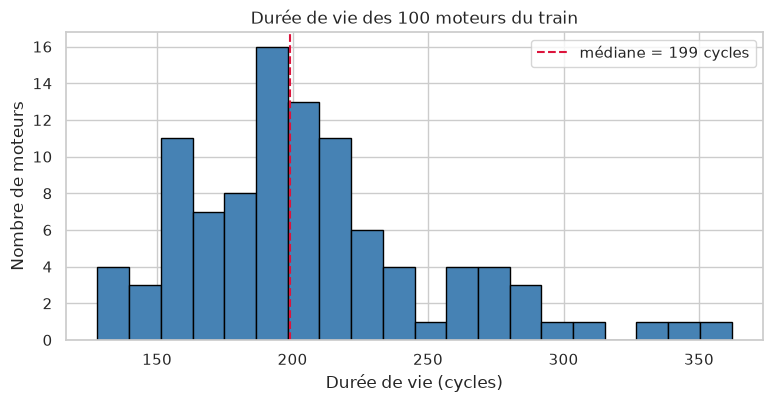

Moteurs qui vivent plus de 300 cycles : [67, 69, 92, 96]


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(train_lengths, bins=20, color="steelblue", edgecolor="black")
ax.axvline(train_lengths.median(), color="crimson", linestyle="--", label=f"médiane = {train_lengths.median():.0f} cycles")
ax.set(xlabel="Durée de vie (cycles)", ylabel="Nombre de moteurs", title="Durée de vie des 100 moteurs du train")
ax.legend()
fig.savefig(FIGURE_DIR / "01_duree_de_vie.png", dpi=150, bbox_inches="tight")
plt.show()

print("Moteurs qui vivent plus de 300 cycles :", train_lengths[train_lengths > 300].index.tolist())

**Ce que nous obtenons.** Les moteurs vivent entre **128 et 362 cycles** (médiane 199, moyenne 206). La plupart vivent entre 150 et 250 cycles ; quatre moteurs dépassent 300 cycles (67, 69, 92 et 96).

**Conclusion.** Les durées de vie sont très variables. Les moteurs longs ne sont pas des erreurs (la section 3 n'a trouvé aucun défaut) : nous les gardons. Il faudra simplement se rappeler que les grandes valeurs de RUL (au-delà de 300) viennent de très peu de moteurs.

## 5. Séparation entraînement / validation

**Ce que nous faisons.** Nous mettons de côté **20 moteurs** pour la validation. Les 80 autres servent à l'analyse et à l'entraînement.

**Pourquoi maintenant ?** Les analyses suivantes vont guider nos choix (quels capteurs garder, etc.). Si elles utilisaient les moteurs de validation, ces moteurs ne seraient plus vraiment « jamais vus ».

**Pourquoi par moteur et pas par ligne ?** Si nous tirions des lignes au hasard, le cycle 100 d'un moteur pourrait être en entraînement et son cycle 101 en validation. Ces deux lignes sont presque identiques : le modèle « reconnaîtrait » le moteur et ses scores seraient trop optimistes. C'est une **fuite d'information**. Toutes les lignes d'un moteur doivent donc rester du même côté.

**Comment.** Nous mélangeons la liste des 100 moteurs avec une graine fixe (le mélange est le même à chaque exécution), puis nous prenons les 20 premiers.

In [10]:
all_engines = np.sort(train_df["unit_id"].unique())                        # [1, 2, ..., 100]
rng = np.random.RandomState(RANDOM_STATE)                                   # générateur aléatoire avec graine
shuffled_engines = rng.permutation(all_engines)                              # mélange la liste des moteurs

validation_engines = sorted(shuffled_engines[:N_VALIDATION_ENGINES].tolist())
analysis_engines = sorted(shuffled_engines[N_VALIDATION_ENGINES:].tolist())

print("Moteurs de validation :", validation_engines)

Moteurs de validation : [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


In [11]:
analysis_df = train_df[train_df["unit_id"].isin(analysis_engines)].copy()
validation_df = train_df[train_df["unit_id"].isin(validation_engines)].copy()

# Vérifications : aucun moteur des deux côtés, aucune ligne perdue.
assert set(analysis_engines).isdisjoint(validation_engines)
assert len(analysis_df) + len(validation_df) == len(train_df)

print("Analyse    :", len(analysis_engines), "moteurs,", len(analysis_df), "lignes")
print("Validation :", len(validation_engines), "moteurs,", len(validation_df), "lignes")

Analyse    : 80 moteurs, 16561 lignes
Validation : 20 moteurs, 4070 lignes


In [12]:
# Les deux groupes ont-ils des durées de vie comparables ?
pd.DataFrame({
    "analyse": train_lengths[analysis_engines].describe(),
    "validation": train_lengths[validation_engines].describe(),
})

,analyse,validation
count,80.000,20.000
mean,207.012,203.500
std,47.456,42.614
min,128.000,135.000
25%,179.750,165.250
50%,199.000,193.500
75%,216.250,240.000
max,362.000,269.000


**Ce que nous obtenons.** 80 moteurs d'analyse (16 561 lignes) et 20 moteurs de validation (4 070 lignes), sans moteur commun. Les durées de vie médianes sont proches (199 et 193,5 cycles).

**Conclusion.** Le partage est correct et reproductible. Une limite : les 4 moteurs les plus longs sont tous en analyse, donc la validation ne contient aucun moteur de plus de 269 cycles.

**À partir d'ici, toutes les analyses utilisent uniquement les 80 moteurs d'analyse.**

## 6. Choix des capteurs

**Ce que nous faisons.** Nous cherchons les colonnes qui ne changent jamais (ou presque).

**Pourquoi.** Une colonne qui garde toujours la même valeur ne peut pas aider à prédire la panne.

**Comment.** Pour chaque colonne, nous comptons son nombre de valeurs différentes avec `nunique()`. Une colonne avec **1 seule valeur** est constante.

In [13]:
measure_columns = SETTING_COLUMNS + SENSOR_COLUMNS
n_unique_values = analysis_df[measure_columns].nunique().sort_values()
n_unique_values

sensor_1        1
setting_3       1
sensor_5        1
sensor_10       1
sensor_18       1
sensor_19       1
sensor_16       1
sensor_6        2
sensor_17      13
setting_2      13
sensor_8       53
sensor_13      55
sensor_20     119
sensor_11     155
setting_1     156
sensor_2      305
sensor_12     425
sensor_7      501
sensor_15    1871
sensor_3     2878
sensor_4     3893
sensor_21    4495
sensor_14    5652
sensor_9     5911
dtype: int64

In [14]:
constant_columns = [c for c in measure_columns if n_unique_values[c] == 1]   # dans l'ordre des colonnes
print("Colonnes constantes :", constant_columns)

# sensor_6 n'a que 2 valeurs : regardons leur fréquence.
print("\nValeurs de sensor_6 (en %) :")
print((analysis_df["sensor_6"].value_counts(normalize=True) * 100).round(1))

# setting_1 et setting_2 varient, mais très peu.
print("\nÉcart-type de setting_1 :", round(analysis_df["setting_1"].std(), 4))
print("Écart-type de setting_2 :", round(analysis_df["setting_2"].std(), 4))

Colonnes constantes : ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Valeurs de sensor_6 (en %) :
sensor_6
21.61    98.1
21.60     1.9
Name: proportion, dtype: float64

Écart-type de setting_1 : 0.0022
Écart-type de setting_2 : 0.0003


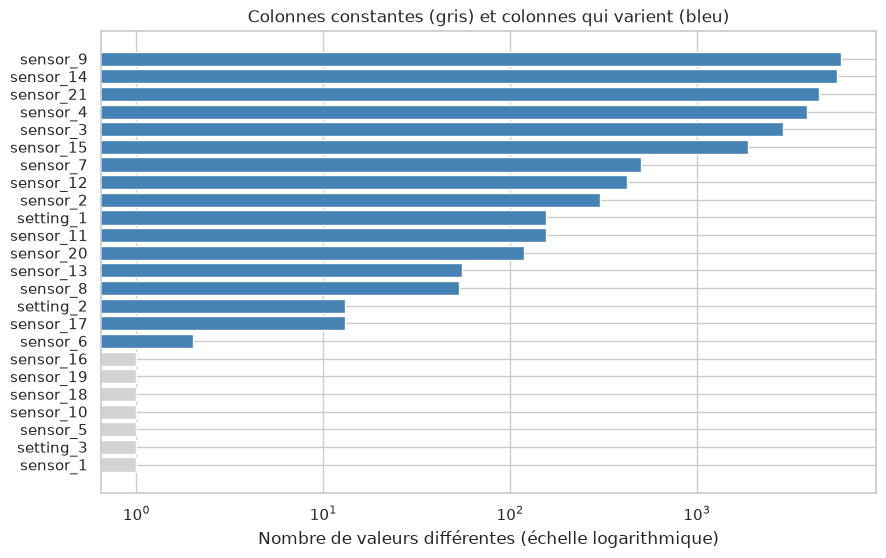

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["lightgray" if n == 1 else "steelblue" for n in n_unique_values]
ax.barh(n_unique_values.index, n_unique_values.values, color=colors)
ax.set_xscale("log")
ax.set(xlabel="Nombre de valeurs différentes (échelle logarithmique)", title="Colonnes constantes (gris) et colonnes qui varient (bleu)")
fig.savefig(FIGURE_DIR / "02_valeurs_distinctes.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que nous obtenons.**

- **7 colonnes constantes** : `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`.
- `sensor_6` ne prend que deux valeurs, dont l'une couvre 98 % des lignes : il est **presque constant**.
- `setting_1` et `setting_2` varient très peu autour de 0 : FD001 n'a qu'une seule condition de fonctionnement.

**Conclusion : nous gardons 14 capteurs.**

`sensor_2`, `3`, `4`, `7`, `8`, `9`, `11`, `12`, `13`, `14`, `15`, `17`, `20`, `21`.

Les 7 colonnes constantes, `sensor_6` et les réglages (`setting_1`, `setting_2`) sont écartés. La section 9 confirmera que ces trois dernières variables n'ont aucun lien avec le RUL.

In [16]:
SELECTED_SENSORS = [s for s in SENSOR_COLUMNS if s not in constant_columns and s != "sensor_6"]
print(len(SELECTED_SENSORS), "capteurs retenus :", SELECTED_SENSORS)

14 capteurs retenus : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 7. Construction de la cible RUL

**Ce que nous faisons.** Nous calculons, pour chaque ligne, le nombre de cycles restant avant la panne.

**Comment.** Dans le train, chaque moteur est suivi jusqu'à la panne. Si un moteur tombe en panne au cycle $T$, alors au cycle $t$ :

$$RUL = T - t$$

> **Exemple.** Un moteur tombe en panne au cycle 5. Au cycle 1, il lui reste 5 − 1 = 4 cycles ; au cycle 5, il lui reste 0. Son RUL vaut donc 4, 3, 2, 1, 0.

En pandas, `groupby("unit_id")["cycle"].transform("max")` donne le dernier cycle du moteur sur chacune de ses lignes. Nous ne gardons pas ce dernier cycle comme colonne : il révèle la date de la panne, que l'on ne connaît pas en situation réelle.

In [17]:
# Vérification sur l'exemple : un moteur qui tombe en panne au cycle 5.
example = pd.DataFrame({"unit_id": [1, 1, 1, 1, 1], "cycle": [1, 2, 3, 4, 5]})
example["RUL"] = example.groupby("unit_id")["cycle"].transform("max") - example["cycle"]
example

,unit_id,cycle,RUL
0,1,1,4
1,1,2,3
2,1,3,2
3,1,4,1
4,1,5,0


In [18]:
analysis_df["RUL"] = analysis_df.groupby("unit_id")["cycle"].transform("max") - analysis_df["cycle"]
validation_df["RUL"] = validation_df.groupby("unit_id")["cycle"].transform("max") - validation_df["cycle"]

# Vérifications : le RUL vaut 0 au dernier cycle de chaque moteur, et n'est jamais négatif.
assert (analysis_df.groupby("unit_id")["RUL"].min() == 0).all()
assert (analysis_df["RUL"] >= 0).all()

analysis_df.loc[analysis_df["unit_id"] == 2, ["unit_id", "cycle", "RUL"]].head()

,unit_id,cycle,RUL
192,2,1,286
193,2,2,285
194,2,3,284
195,2,4,283
196,2,5,282


### RUL brut ou RUL plafonné ?

En début de vie, un moteur est en bonne santé et ses capteurs bougent très peu (voir section 8). Il est donc très difficile de savoir s'il lui reste 250 ou 300 cycles.

Une solution classique est le **RUL plafonné** : on remplace le RUL par `min(RUL, plafond)`. Avec un plafond de 125, un moteur à qui il reste 277 cycles reçoit la valeur 125, qui veut dire « au moins 125 cycles ». Un moteur à qui il en reste 80 garde la valeur 80.

La valeur du plafond sera **choisie dans la baseline**, en comparant plusieurs valeurs sur la validation. Ici, 125 sert seulement d'illustration.

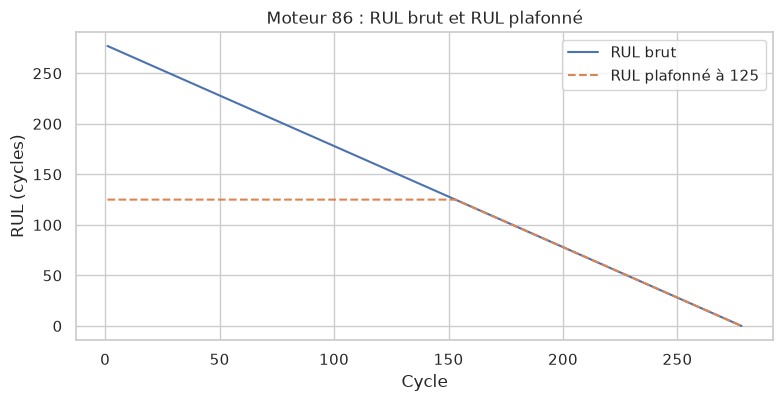

In [19]:
engine_86 = analysis_df[analysis_df["unit_id"] == 86]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(engine_86["cycle"], engine_86["RUL"], label="RUL brut")
ax.plot(engine_86["cycle"], engine_86["RUL"].clip(upper=125), linestyle="--", label="RUL plafonné à 125")
ax.set(xlabel="Cycle", ylabel="RUL (cycles)", title="Moteur 86 : RUL brut et RUL plafonné")
ax.legend()
fig.savefig(FIGURE_DIR / "03_rul_brut_vs_plafonne.png", dpi=150, bbox_inches="tight")
plt.show()

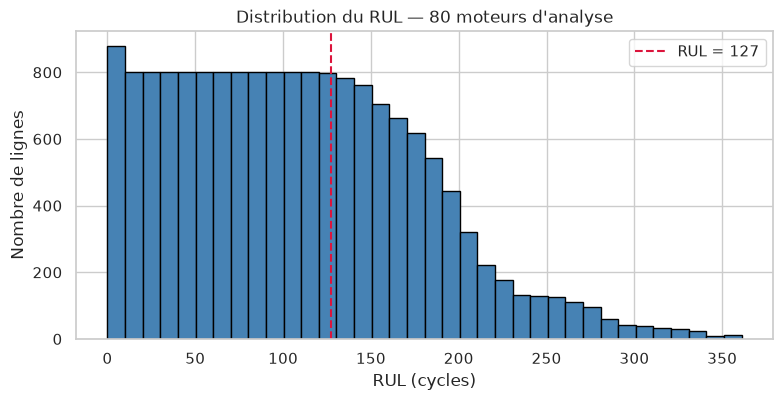

Durée de vie la plus courte : 128 cycles -> zone RUL <= 127
Part des lignes avec RUL <= 127 : 61.8 %


In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(analysis_df["RUL"], bins=36, color="steelblue", edgecolor="black")
ax.axvline(127, color="crimson", linestyle="--", label="RUL = 127")
ax.set(xlabel="RUL (cycles)", ylabel="Nombre de lignes", title="Distribution du RUL — 80 moteurs d'analyse")
ax.legend()
fig.savefig(FIGURE_DIR / "04_distribution_rul.png", dpi=150, bbox_inches="tight")
plt.show()

# Le moteur le plus court vit 128 cycles : tous les moteurs ont donc une ligne pour chaque RUL de 0 à 127.
EVAL_HORIZON = int(train_lengths[analysis_engines].min()) - 1
print("Durée de vie la plus courte :", train_lengths[analysis_engines].min(), "cycles -> zone RUL <=", EVAL_HORIZON)
print("Part des lignes avec RUL <=", EVAL_HORIZON, ":", round((analysis_df["RUL"] <= EVAL_HORIZON).mean() * 100, 1), "%")

**Ce que nous obtenons.** L'histogramme est plat de 0 à 127, puis il diminue.

**Pourquoi cette forme ?** Le moteur d'analyse le plus court vit 128 cycles. Chacun des 80 moteurs fournit donc exactement une ligne pour chaque RUL entre 0 et 127. Au-delà, seuls les moteurs qui ont vécu plus longtemps donnent des lignes, d'où la diminution.

**Conclusion.**

- La zone **RUL ≤ 127** est bien couverte par tous les moteurs. C'est aussi la zone utile pour la maintenance, puisque c'est là qu'il faut anticiper la panne. La baseline évaluera les modèles en priorité dans cette zone.
- Les grands RUL reposent sur peu de moteurs : c'est un argument de plus pour plafonner le RUL.

## 8. Évolution des capteurs avant la panne

**Ce que nous faisons.** Pour chacun des 14 capteurs, nous traçons la valeur du capteur en fonction du RUL, pour les 80 moteurs.

**Pourquoi.** Pour prédire la panne, un capteur doit **changer** quand la panne approche.

**Comment.**

- L'axe horizontal est le RUL, **inversé** : la panne (RUL = 0) est à droite.
- Les mesures sont bruitées. Nous traçons donc une **moyenne glissante** sur 10 cycles : à chaque cycle, la moyenne des 10 derniers cycles du moteur. Elle n'utilise que le passé, comme en situation réelle.

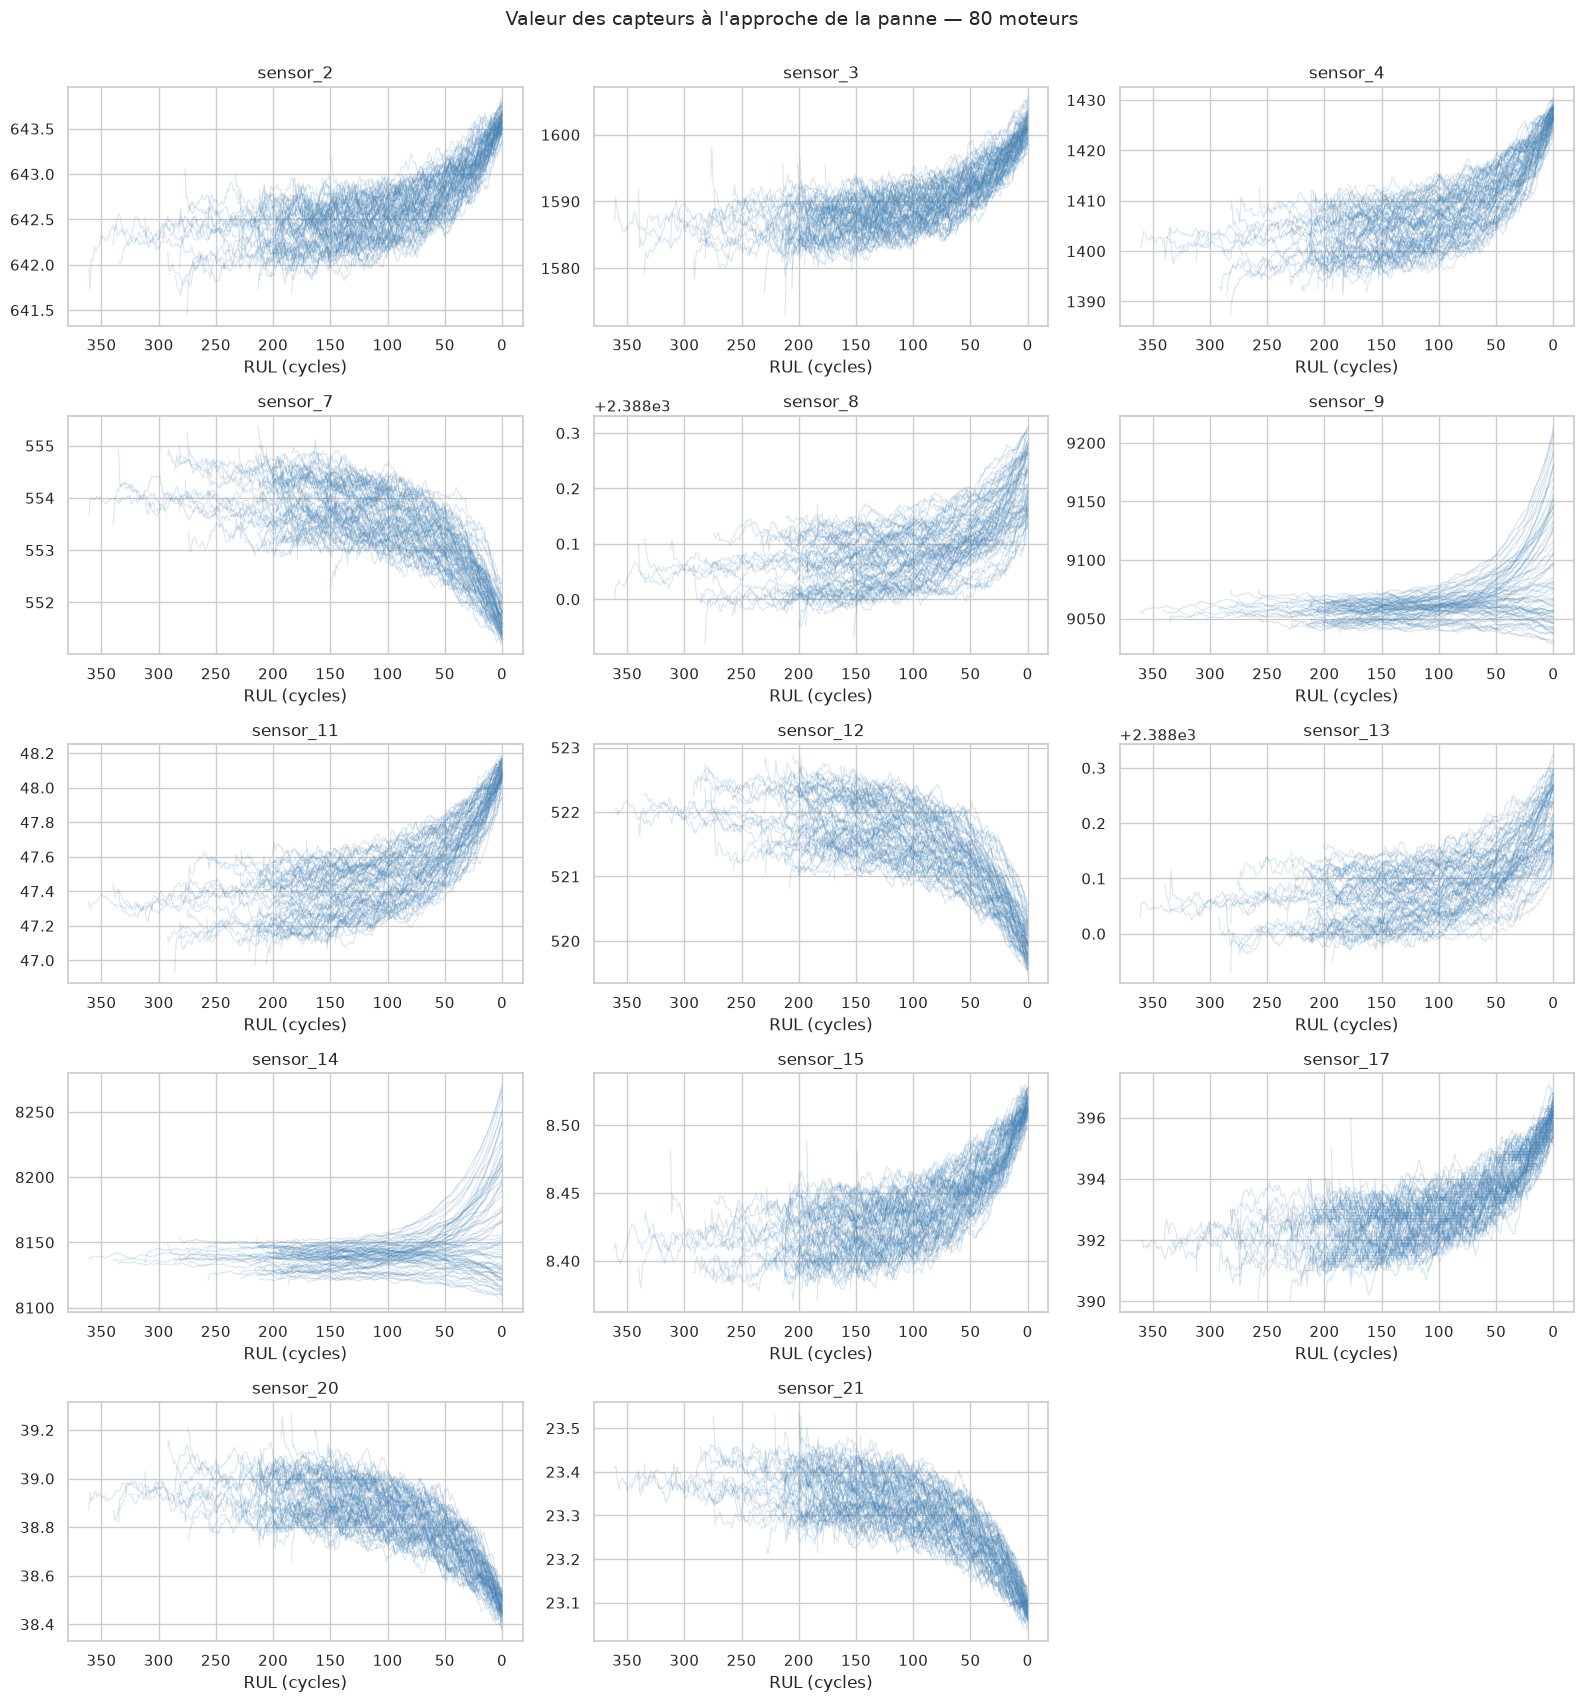

In [21]:
fig, axes = plt.subplots(5, 3, figsize=(16, 17))
axes = axes.ravel()

for ax, sensor in zip(axes, SELECTED_SENSORS):
    for engine_id, engine in analysis_df.groupby("unit_id"):
        smoothed = engine[sensor].rolling(window=10, min_periods=1).mean()   # moyenne des 10 derniers cycles
        ax.plot(engine["RUL"], smoothed, color="steelblue", alpha=0.2, linewidth=0.8)
    ax.invert_xaxis()                                                        # la panne (RUL = 0) à droite
    ax.set_title(sensor)
    ax.set_xlabel("RUL (cycles)")

axes[-1].axis("off")   # la 15e case de la grille est vide
fig.suptitle("Valeur des capteurs à l'approche de la panne — 80 moteurs", fontsize=14, y=1.0)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_capteurs_vs_rul.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que nous obtenons.**

- **12 capteurs** évoluent clairement à l'approche de la panne : 8 augmentent (`sensor_2`, `3`, `4`, `8`, `11`, `13`, `15`, `17`) et 4 diminuent (`sensor_7`, `12`, `20`, `21`).
- L'évolution est **lente puis accélérée** : les courbes sont presque plates quand le RUL est grand, puis elles bougent de plus en plus vite sur les 100 à 150 derniers cycles.
- Les moteurs **ne partent pas tous du même niveau** : chaque moteur a son propre point de départ. Pour la plupart des capteurs, les courbes se rapprochent ensuite au moment de la panne (moins nettement pour `sensor_8` et `sensor_13`).
- `sensor_9` et `sensor_14` se comportent différemment : en fin de vie, ils montent fortement pour certains moteurs et baissent légèrement pour d'autres.

**Conclusion pour SentinelX AI.**

1. Les capteurs contiennent bien un signal de dégradation : prédire le RUL est possible.
2. Le début de vie donne peu d'information sur le RUL exact, ce qui confirme l'intérêt du RUL plafonné.
3. Une mesure isolée est bruitée et dépend du niveau de départ du moteur. Il sera utile de donner au modèle l'**historique récent** : la moyenne des derniers cycles, la tendance (est-ce que ça monte vite ?) et l'écart par rapport au début de vie du moteur.

## 9. Lien entre les capteurs et le RUL

**Ce que nous faisons.** Nous mesurons, pour chaque variable, la force de son lien avec le RUL grâce à la **corrélation**.

> **Corrélation.** Un nombre entre −1 et +1. Proche de +1 : les deux variables augmentent ensemble. Proche de −1 : l'une augmente quand l'autre diminue. Proche de 0 : pas de lien.
>
> - **Pearson** mesure un lien **en ligne droite**.
> - **Spearman** mesure un lien **toujours dans le même sens**, même si ce n'est pas une ligne droite.

**Exemple.** Pour $y = x^3$, $y$ augmente toujours quand $x$ augmente (Spearman = 1), mais pas en ligne droite (Pearson < 1).

In [22]:
x = pd.Series(range(1, 11))
y = x ** 3
print("Pearson  :", round(x.corr(y, method="pearson"), 3))
print("Spearman :", round(x.corr(y, method="spearman"), 3))

Pearson  : 0.928
Spearman : 1.0


In [23]:
# Corrélation de chaque variable avec le RUL (80 moteurs d'analyse).
variables = ["cycle"] + SELECTED_SENSORS + ["sensor_6", "setting_1", "setting_2"]
correlations = pd.DataFrame({
    "pearson": analysis_df[variables].corrwith(analysis_df["RUL"], method="pearson"),
    "spearman": analysis_df[variables].corrwith(analysis_df["RUL"], method="spearman"),
})
correlations["abs_spearman"] = correlations["spearman"].abs()           # force du lien, sans le signe
correlations = correlations.sort_values("abs_spearman", ascending=False)
correlations.round(2)

,pearson,spearman,abs_spearman
cycle,-0.72,-0.78,0.78
sensor_11,-0.68,-0.71,0.71
sensor_4,-0.67,-0.69,0.69
sensor_12,0.66,0.68,0.68
sensor_7,0.64,0.67,0.67
sensor_15,-0.63,-0.66,0.66
sensor_21,0.62,0.65,0.65
sensor_20,0.62,0.65,0.65
sensor_17,-0.60,-0.62,0.62
sensor_2,-0.60,-0.62,0.62


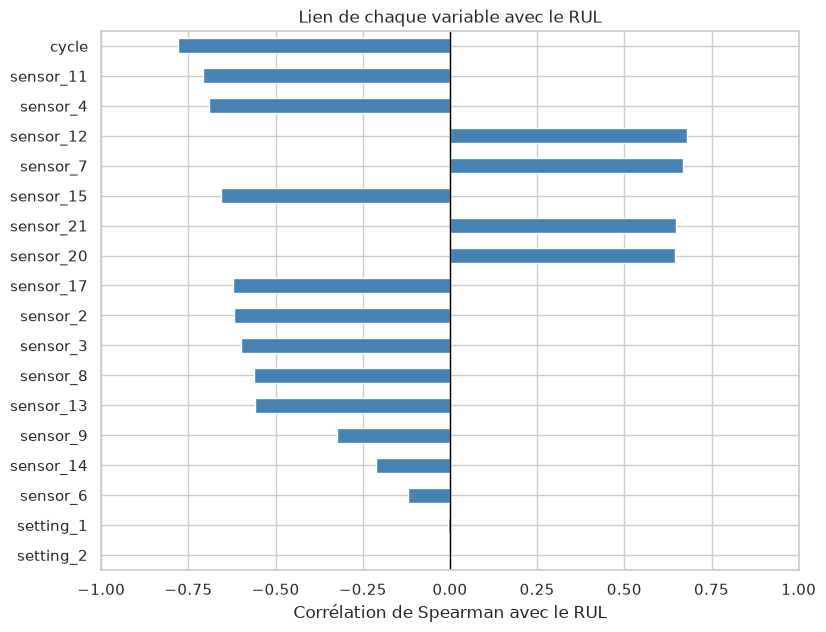

In [24]:
fig, ax = plt.subplots(figsize=(9, 7))
correlations.sort_values("abs_spearman")["spearman"].plot.barh(ax=ax, color="steelblue")
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Corrélation de Spearman avec le RUL", xlim=(-1, 1), title="Lien de chaque variable avec le RUL")
fig.savefig(FIGURE_DIR / "06_correlations_rul.png", dpi=150, bbox_inches="tight")
plt.show()

**Comment lire le signe.** Une corrélation **négative** avec le RUL signifie que le capteur **augmente** quand le RUL diminue, donc quand la panne approche.

**Ce que nous obtenons.**

- **12 capteurs** ont un lien net avec le RUL : Spearman entre 0,56 et 0,71 en valeur absolue (le plus fort : `sensor_11`, −0,71).
- Pour presque tous, Spearman est un peu plus fort que Pearson : le lien va toujours dans le même sens, mais ce n'est pas une ligne droite. Cela confirme la dégradation « lente puis accélérée » vue en section 8.
- `sensor_9` et `sensor_14` ont un lien faible (−0,32 et −0,21), à cause de leurs deux comportements différents selon les moteurs.
- `sensor_6`, `setting_1` et `setting_2` n'ont pratiquement **aucun lien** avec le RUL (au plus 0,12 en valeur absolue), ce qui confirme leur exclusion.
- `cycle` (−0,78) est lié mécaniquement au RUL : pour un même moteur, RUL = T − cycle. Nous ne l'utilisons pas comme entrée, pour que le modèle apprenne l'**état** du moteur à partir des capteurs, et pas seulement son âge.

**Conclusion.** Une corrélation décrit un lien, elle ne prouve pas qu'une variable est utile ni qu'elle cause la panne. Nous **gardons `sensor_9` et `sensor_14`** malgré leur lien faible : leur comportement en fin de vie peut aider un modèle non linéaire, et la baseline pourra le vérifier.

## 10. Capteurs redondants

**Ce que nous faisons.** Nous cherchons les paires de capteurs qui donnent presque la même information.

**Pourquoi.** Deux capteurs très corrélés entre eux sont en partie **redondants**. Ce n'est pas grave pour une forêt aléatoire, mais une régression linéaire peut devenir instable (ses coefficients peuvent varier fortement).

**Comment.** Nous calculons la matrice des corrélations entre les 14 capteurs, puis nous listons les paires dont la corrélation dépasse 0,80 en valeur absolue.

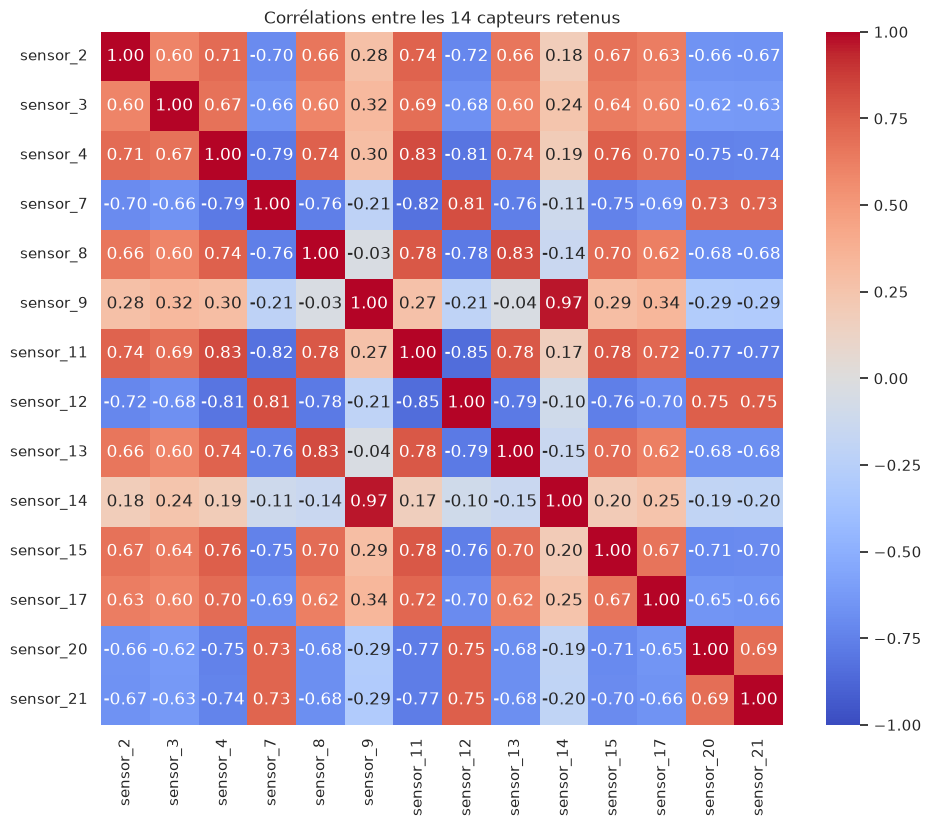

In [25]:
sensor_correlations = analysis_df[SELECTED_SENSORS].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(sensor_correlations, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations entre les 14 capteurs retenus")
fig.savefig(FIGURE_DIR / "07_matrice_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
strong_pairs = []
for i, sensor_a in enumerate(SELECTED_SENSORS):
    for sensor_b in SELECTED_SENSORS[i + 1:]:            # chaque paire une seule fois
        value = sensor_correlations.loc[sensor_a, sensor_b]
        if abs(value) >= 0.80:
            strong_pairs.append({"capteur_1": sensor_a, "capteur_2": sensor_b, "corrélation": round(value, 2)})

strong_pairs = pd.DataFrame(strong_pairs)
strong_pairs["abs_corrélation"] = strong_pairs["corrélation"].abs()
strong_pairs = strong_pairs.sort_values("abs_corrélation", ascending=False).drop(columns="abs_corrélation")
strong_pairs

,capteur_1,capteur_2,corrélation
5,sensor_9,sensor_14,0.97
6,sensor_11,sensor_12,-0.85
0,sensor_4,sensor_11,0.83
4,sensor_8,sensor_13,0.83
2,sensor_7,sensor_11,-0.82
1,sensor_4,sensor_12,-0.81
3,sensor_7,sensor_12,0.81


**Ce que nous obtenons.** 7 paires dépassent 0,80. La plus forte est `sensor_9` / `sensor_14` (0,97). Les autres relient `sensor_4`, `7`, `11`, `12` entre eux, et `sensor_8` à `sensor_13`.

**Conclusion.** Une partie de cette redondance vient simplement du fait que ces capteurs évoluent tous avec la dégradation. **Nous gardons les 14 capteurs.** La forêt aléatoire gère bien la redondance, et pour la régression linéaire, seule l'interprétation des coefficients serait gênée, pas la qualité des prédictions.

## 11. Vérification du jeu de test

**Ce que nous faisons.** Nous vérifions les **entrées** du test (sans regarder son RUL réel).

**Pourquoi.** Les moteurs de test sont arrêtés avant la panne. Il faut savoir combien de cycles d'historique ils ont, car la baseline et le futur LSTM/GRU (des réseaux de neurones qui lisent une séquence de cycles) utiliseront les 30 derniers cycles de chaque moteur.

In [27]:
print("Valeurs manquantes :", test_df.isna().sum().sum())
print("Lignes en double   :", test_df.duplicated().sum())

test_lengths = test_df.groupby("unit_id")["cycle"].max()
print("\nNombre de cycles observés par moteur de test :")
print(test_lengths.describe().round(1))
print("\nMoteurs de test avec moins de 30 cycles :", (test_lengths < 30).sum())
print("Moteurs de test avec moins de 50 cycles :", (test_lengths < 50).sum())

HISTORY_WINDOW = 30   # historique utilisé par la baseline : possible pour tous les moteurs de test (au moins 31 cycles)

Valeurs manquantes : 0
Lignes en double   : 0

Nombre de cycles observés par moteur de test :
count    100.0
mean     131.0
std       53.6
min       31.0
25%       88.8
50%      133.5
75%      164.2
max      303.0
Name: cycle, dtype: float64

Moteurs de test avec moins de 30 cycles : 0
Moteurs de test avec moins de 50 cycles : 7


In [28]:
# Les colonnes constantes du train sont-elles aussi constantes dans le test ?
print("Nombre de valeurs dans le test :", test_df[constant_columns].nunique().to_dict())

Nombre de valeurs dans le test : {'setting_3': 1, 'sensor_1': 1, 'sensor_5': 1, 'sensor_10': 1, 'sensor_16': 1, 'sensor_18': 1, 'sensor_19': 1}


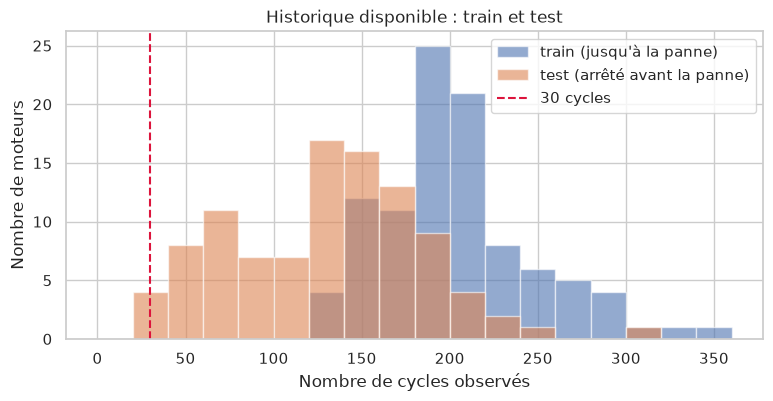

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = range(0, 380, 20)
ax.hist(train_lengths, bins=bins, alpha=0.6, label="train (jusqu'à la panne)")
ax.hist(test_lengths, bins=bins, alpha=0.6, label="test (arrêté avant la panne)")
ax.axvline(30, color="crimson", linestyle="--", label="30 cycles")
ax.set(xlabel="Nombre de cycles observés", ylabel="Nombre de moteurs", title="Historique disponible : train et test")
ax.legend()
fig.savefig(FIGURE_DIR / "08_longueurs_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce que nous obtenons.** Le test est propre. Ses moteurs ont entre 31 et 303 cycles d'historique (médiane 133,5). Aucun n'en a moins de 30, mais 7 en ont moins de 50. Les colonnes constantes du train sont aussi constantes dans le test.

**Conclusion.** Une fenêtre d'historique de **30 cycles au maximum** fonctionne pour tous les moteurs de test. Avec 50 cycles, il faudrait une solution particulière pour 7 moteurs. La baseline utilisera donc 30 cycles, et ce choix est aussi valable pour le futur LSTM/GRU.

## 12. Règles contre la fuite d'information et export

### Les règles que la baseline doit respecter

| Règle | Pourquoi |
|---|---|
| Séparer les données **par moteur** | les cycles d'un même moteur se ressemblent trop |
| Ne jamais utiliser `unit_id` comme entrée | le modèle mémoriserait des moteurs au lieu d'apprendre la dégradation |
| Ne jamais utiliser le dernier cycle du moteur, ni le pourcentage de vie écoulé | ils révèlent la date de la panne |
| Calculer l'historique avec le **passé uniquement** | en situation réelle, le futur n'existe pas encore |
| Choisir les réglages sur la **validation**, jamais sur le test | sinon le score final serait trop optimiste |
| Lire `RUL_FD001.txt` **une seule fois**, à la fin | c'est l'examen final du modèle |

### Export des décisions

Nous enregistrons nos décisions dans des fichiers JSON. Le notebook de baseline les relira, au lieu de recopier des valeurs à la main.

In [30]:
engine_split = {
    "dataset": "FD001",
    "method": "permutation aléatoire des 100 moteurs (graine 42), 20 premiers = validation",
    "random_state": RANDOM_STATE,
    "analysis_engines": analysis_engines,
    "validation_engines": validation_engines,
}

feature_groups = {
    "constant_columns": constant_columns,
    "excluded_columns": ["sensor_6", "setting_1", "setting_2"],
    "selected_sensors": SELECTED_SENSORS,
    "redundant_pairs": strong_pairs.to_dict("records"),
    "forbidden_as_feature": ["unit_id", "RUL", "last_cycle", "life_pct"],
}

eda_summary = {
    "raw_files_sha256": {"train_FD001.txt": train_sha256, "test_FD001.txt": test_sha256},
    "train_rows": len(train_df),
    "test_rows": len(test_df),
    "train_length_min_max": [int(train_lengths.min()), int(train_lengths.max())],
    "test_length_min_max": [int(test_lengths.min()), int(test_lengths.max())],
    "evaluation_horizon": EVAL_HORIZON,
    "history_window": HISTORY_WINDOW,
}

for filename, content in [("fd001_engine_split.json", engine_split),
                          ("fd001_feature_groups.json", feature_groups),
                          ("eda_fd001_summary.json", eda_summary)]:
    (ARTIFACT_DIR / filename).write_text(json.dumps(content, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Enregistré :", ARTIFACT_DIR / filename)

Enregistré : ../artifacts/eda_fd001/fd001_engine_split.json
Enregistré : ../artifacts/eda_fd001/fd001_feature_groups.json
Enregistré : ../artifacts/eda_fd001/eda_fd001_summary.json


## 13. Synthèse

**1. Qu'avons-nous appris sur les données ?**
Les données sont propres : pas de valeur manquante, pas de doublon, des cycles continus. Le train contient 100 moteurs suivis jusqu'à la panne, avec des durées de vie de 128 à 362 cycles. Les capteurs se dégradent lentement, puis de plus en plus vite avant la panne, et chaque moteur part de son propre niveau.

**2. Quels capteurs semblent utiles, et pourquoi ?**
14 capteurs varient. Douze d'entre eux évoluent clairement vers la panne (corrélation de Spearman de 0,56 à 0,71 en valeur absolue). `sensor_9` et `sensor_14` ont un comportement double, mais nous les gardons. Les 7 colonnes constantes, `sensor_6` et les réglages n'apportent rien.

**3. Quels problèmes avons-nous détectés ?**

| Problème | Ce que nous faisons |
|---|---|
| Les lignes d'un même moteur se ressemblent | séparation par moteur (80 / 20) |
| Les mesures sont bruitées | utiliser une moyenne sur les derniers cycles |
| Chaque moteur part d'un niveau différent | mesurer l'écart par rapport au début de vie du moteur |
| Le RUL est peu prévisible en début de vie | tester un RUL plafonné |
| Certains capteurs sont redondants | gardés : sans effet sur la qualité des prédictions |
| Certains moteurs de test n'ont que 31 cycles | historique de 30 cycles au maximum |

**4. Comment construisons-nous le RUL ?**
RUL = dernier cycle du moteur − cycle courant, calculé moteur par moteur et vérifié automatiquement.

**5. Quelles décisions transmettons-nous à la baseline ?**
Le partage 80 / 20 moteurs (`fd001_engine_split.json`), les 14 capteurs retenus (`fd001_feature_groups.json`), une évaluation centrée sur la zone RUL ≤ 127, un historique de 30 cycles, un plafond de RUL à choisir sur la validation, et les règles contre la fuite d'information.

**Limites.** Les données sont simulées. FD001 ne contient qu'une condition de fonctionnement et un type de panne. Enfin, la validation ne compte que 20 moteurs.

### Vérification automatique des chiffres cités

La cellule suivante recalcule les chiffres écrits dans ce notebook. Si les données ou le code changent, elle s'arrête avec une erreur au lieu de laisser un texte faux.

In [31]:
assert len(train_df) == 20631 and len(test_df) == 13096
assert len(engine_1) == 192
assert train_lengths.min() == 128 and train_lengths.max() == 362 and train_lengths.median() == 199
assert round(train_lengths.mean()) == 206
assert sorted(train_lengths[train_lengths > 300].index.tolist()) == [67, 69, 92, 96]
assert validation_engines == [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]
assert len(analysis_df) == 16561 and len(validation_df) == 4070
assert train_lengths[validation_engines].max() == 269 and train_lengths[validation_engines].median() == 193.5
assert sorted(constant_columns) == sorted(["setting_3", "sensor_1", "sensor_5", "sensor_10", "sensor_16", "sensor_18", "sensor_19"])
assert round(analysis_df["sensor_6"].value_counts(normalize=True).iloc[0] * 100) == 98
assert len(SELECTED_SENSORS) == 14
assert train_lengths[analysis_engines].min() == 128 and EVAL_HORIZON == 127
spearman = correlations["spearman"]
assert round(spearman["sensor_11"], 2) == -0.71 and round(spearman["cycle"], 2) == -0.78
strong_sensors = [s for s in SELECTED_SENSORS if s not in ("sensor_9", "sensor_14")]
assert spearman[strong_sensors].abs().round(2).between(0.56, 0.71).all()
assert round(spearman["sensor_9"], 2) == -0.32 and round(spearman["sensor_14"], 2) == -0.21
assert spearman[["sensor_6", "setting_1", "setting_2"]].abs().max() < 0.12
assert len(strong_pairs) == 7 and strong_pairs.iloc[0]["corrélation"] == 0.97
assert test_lengths.min() == 31 and test_lengths.max() == 303 and test_lengths.median() == 133.5
assert (test_lengths < 30).sum() == 0 and (test_lengths < 50).sum() == 7
print("Tous les chiffres cités correspondent à l'exécution.")

Tous les chiffres cités correspondent à l'exécution.
